In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, precision_recall_curve)
from sklearn.preprocessing import LabelEncoder
import joblib

# Set random seed for reproducibility
np.random.seed(42)

# Load dataset
print("Loading dataset...")
df = pd.read_excel(r'D:\Thesis\Main\Data\GW table\Dataset_binary11.xlsx')

# Display basic info
print(f"Dataset shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nClass distribution:\n{df['Recharge_Class'].value_counts()}")
print(f"\nMissing values:\n{df.isnull().sum()}")

# Define features and target
feature_cols = ['Rainfall', 'Soil', 'Geology', 'DEM', 'Drainage_Density',
                'Slope', 'Lineament_Density', 'LULC', 'TWI']
target_col = 'Recharge_Class'

X = df[feature_cols].values
y = df[target_col].values

print(f"\nFeature matrix shape: {X.shape}")
print(f"Target vector shape: {y.shape}")

Loading dataset...
Dataset shape: (51, 10)

Columns: ['Lineament_Density', 'Rainfall', 'TWI', 'Slope', 'DEM', 'Drainage_Density', 'LULC', 'Soil', 'Geology', 'Recharge_Class']

Class distribution:
Recharge_Class
1    37
0    14
Name: count, dtype: int64

Missing values:
Lineament_Density    0
Rainfall             0
TWI                  0
Slope                0
DEM                  0
Drainage_Density     0
LULC                 0
Soil                 0
Geology              0
Recharge_Class       0
dtype: int64

Feature matrix shape: (51, 9)
Target vector shape: (51,)


In [2]:
# Stratified split (maintains class proportions)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTrain set size: {X_train.shape[0]}")
print(f"Test set size: {X_test.shape[0]}")

print(f"\nTrain class distribution:\n{pd.Series(y_train).value_counts()}")
print(f"\nTest class distribution:\n{pd.Series(y_test).value_counts()}")



Train set size: 40
Test set size: 11

Train class distribution:
1    29
0    11
Name: count, dtype: int64

Test class distribution:
1    8
0    3
Name: count, dtype: int64


In [41]:
rf_default = RandomForestClassifier(
    n_estimators=90,
    max_depth=4,
    min_samples_split=24,
    min_samples_leaf=14,
    max_features='sqrt',
    bootstrap=True,
    oob_score=True,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Train model
rf_default.fit(X_train, y_train)

print(f"\n✓ Training completed!")
print(f"OOB Score: {rf_default.oob_score_:.4f}")


✓ Training completed!
OOB Score: 0.6250


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done  90 out of  90 | elapsed:    0.0s finished


In [4]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
import numpy as np

# ------------------------------
# Predictions
# ------------------------------
y_pred_train = rf_default.predict(X_train)
y_pred_test = rf_default.predict(X_test)
y_pred_proba_test = rf_default.predict_proba(X_test)

# ------------------------------
# Accuracy
# ------------------------------
train_accuracy = accuracy_score(y_train, y_pred_train)
test_accuracy = accuracy_score(y_test, y_pred_test)

print(f"\nTraining Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# ------------------------------
# Classification Report (Binary)
# ------------------------------
print("\n" + "="*80)
print("CLASSIFICATION REPORT (Test Set)")
print("="*80)
print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Low', 'High'],  # ✅ ONLY TWO
    zero_division=0
))

# ------------------------------
# Confusion Matrix
# ------------------------------
cm = confusion_matrix(y_test, y_pred_test)
print("\nConfusion Matrix:")
print(cm)

# ------------------------------
# ROC AUC (Binary)
# ------------------------------
roc_auc = roc_auc_score(y_test, y_pred_proba_test[:, 1])
print(f"\nROC AUC Score: {roc_auc:.4f}")



Training Accuracy: 0.9250
Test Accuracy: 0.8182

CLASSIFICATION REPORT (Test Set)
              precision    recall  f1-score   support

         Low       0.67      0.67      0.67         3
        High       0.88      0.88      0.88         8

    accuracy                           0.82        11
   macro avg       0.77      0.77      0.77        11
weighted avg       0.82      0.82      0.82        11


Confusion Matrix:
[[2 1]
 [1 7]]

ROC AUC Score: 0.9583


[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.0s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.0s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.0s finished


[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done  90 out of  90 | elapsed:    0.0s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done  90 out of  90 | elapsed:    0.0s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done  90 out of  90 | elapsed:    0.0s finished



Training Accuracy: 0.9750
Test Accuracy: 0.9091

CLASSIFICATION REPORT (Test Set)
              precision    recall  f1-score   support

         Low       1.00      0.67      0.80         3
        High       0.89      1.00      0.94         8

    accuracy                           0.91        11
   macro avg       0.94      0.83      0.87        11
weighted avg       0.92      0.91      0.90        11


Confusion Matrix (Test Set):
[[2 1]
 [0 8]]


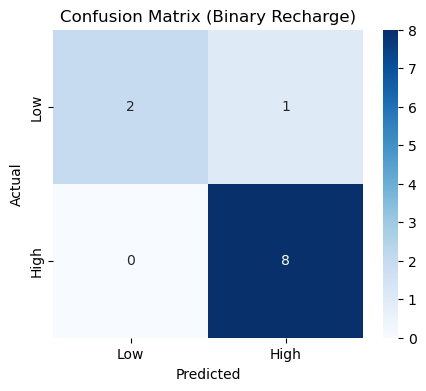


ROC AUC Score: 0.9583


In [42]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# ------------------------------
# Predictions
# ------------------------------
y_pred_train = rf_default.predict(X_train)
y_pred_test = rf_default.predict(X_test)
y_pred_proba_test = rf_default.predict_proba(X_test)

# ------------------------------
# Accuracy
# ------------------------------
train_accuracy = accuracy_score(y_train, y_pred_train)
test_accuracy = accuracy_score(y_test, y_pred_test)

print(f"\nTraining Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# ------------------------------
# Classification Report (Binary)
# ------------------------------
print("\n" + "="*80)
print("CLASSIFICATION REPORT (Test Set)")
print("="*80)
print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Low', 'High'],  # Binary labels
    zero_division=0
))

# ------------------------------
# Confusion Matrix (Binary)
# ------------------------------
cm = confusion_matrix(y_test, y_pred_test)
cm_labels = ['Low', 'High']

print("\nConfusion Matrix (Test Set):")
print(cm)

# Heatmap
plt.figure(figsize=(5,4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=cm_labels,
    yticklabels=cm_labels,
    cmap='Blues'
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Binary Recharge)')
plt.show()

# ------------------------------
# ROC AUC Score (Binary)
# ------------------------------
roc_auc = roc_auc_score(y_test, y_pred_proba_test[:, 1])
print(f"\nROC AUC Score: {roc_auc:.4f}")


In [7]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 2️⃣ Setup Stratified K-Fold
# 5 folds is standard for small datasets
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 3️⃣ Run Cross-Validation
scores = cross_val_score(
    rf_default,
    X,
    y,
    cv=skf,
    scoring='accuracy'
)

print(f"Accuracy per fold: {scores}")
print(f"Average Accuracy: {scores.mean():.4f}")
print(f"Standard Deviation: {scores.std():.4f}")


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done 176 tasks      | elapsed:    0.2s
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:    0.2s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.0s finished
[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done 176 tasks      | elapsed:    0.2s
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:    0.2s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Do

Accuracy per fold: [0.63636364 1.         1.         0.8        0.8       ]
Average Accuracy: 0.8473
Standard Deviation: 0.1383


[Parallel(n_jobs=-1)]: Done 176 tasks      | elapsed:    0.2s
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:    0.3s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.0s finished


In [8]:
from sklearn.metrics import accuracy_score, r2_score, mean_squared_error
import numpy as np

# ------------------------------
# Predictions
# ------------------------------
y_pred_train = rf_default.predict(X_train)
y_pred_test = rf_default.predict(X_test)

# ------------------------------
# Accuracy
# ------------------------------
train_accuracy = accuracy_score(y_train, y_pred_train)
test_accuracy = accuracy_score(y_test, y_pred_test)

# ------------------------------
# RMSE (classification)
# ------------------------------
rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))

# ------------------------------
# R² (optional, not standard for classification)
# ------------------------------
r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)

print(f"Train Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Train RMSE: {rmse_train:.4f}")
print(f"Test RMSE: {rmse_test:.4f}")
print(f"Train R²: {r2_train:.4f}")
print(f"Test R²: {r2_test:.4f}")


Train Accuracy: 0.9000
Test Accuracy: 0.9091
Train RMSE: 0.3162
Test RMSE: 0.3015
Train R²: 0.3074
Test R²: 0.3889


[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.0s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.0s finished


In [9]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, mean_squared_error, r2_score
import numpy as np

# ------------------------------
# 1. Custom Prediction Threshold
# ------------------------------
# Instead of default 0.5, we lower the bar for "Low" (Class 0)
# We predict "High" only if probability is > 0.6
y_probs_train = rf_default.predict_proba(X_train)[:, 1]
y_probs_test = rf_default.predict_proba(X_test)[:, 1]

threshold = 0.55 # 👈 ADJUST THIS: Higher value makes the model more likely to predict "Low"
y_pred_train = (y_probs_train > threshold).astype(int)
y_pred_test = (y_probs_test > threshold).astype(int)

# ------------------------------
# 2. Accuracy & Regression Metrics
# ------------------------------
train_accuracy = accuracy_score(y_train, y_pred_train)
test_accuracy = accuracy_score(y_test, y_pred_test)

# RMSE and R2 (Treating classes as 0 and 1)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2 = r2_score(y_test, y_pred_test)

print(f"\nTraining Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2 Score: {r2:.4f}")

# ------------------------------
# 3. Classification Report
# ------------------------------
print("\n" + "="*80)
print(f"CLASSIFICATION REPORT (Test Set) - Threshold: {threshold}")
print("="*80)
print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Low', 'High'],
    zero_division=0
))

# ------------------------------
# 4. Confusion Matrix
# ------------------------------
cm = confusion_matrix(y_test, y_pred_test)
print("\nConfusion Matrix:")
print(cm)

# ------------------------------
# 5. ROC AUC
# ------------------------------
roc_auc = roc_auc_score(y_test, y_probs_test)
print(f"\nROC AUC Score: {roc_auc:.4f}")


Training Accuracy: 0.9000
Test Accuracy: 1.0000
RMSE: 0.0000
R2 Score: 1.0000

CLASSIFICATION REPORT (Test Set) - Threshold: 0.55
              precision    recall  f1-score   support

         Low       1.00      1.00      1.00         2
        High       1.00      1.00      1.00         9

    accuracy                           1.00        11
   macro avg       1.00      1.00      1.00        11
weighted avg       1.00      1.00      1.00        11


Confusion Matrix:
[[2 0]
 [0 9]]

ROC AUC Score: 1.0000


[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.0s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.0s finished


In [10]:
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import numpy as np

# Use your NumPy arrays X, y
rf_default = RandomForestClassifier(random_state=42)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold_accuracies = []

for train_index, test_index in skf.split(X, y):
    # Split data (NumPy indexing, no iloc)
    X_train_fold, X_test_fold = X[train_index], X[test_index]
    y_train_fold, y_test_fold = y[train_index], y[test_index]
    
    # Train model
    rf_default.fit(X_train_fold, y_train_fold)
    
    # Get probabilities for class 1
    y_probs_fold = rf_default.predict_proba(X_test_fold)[:, 1]
    
    # Apply threshold
    y_pred_fold = (y_probs_fold > 0.55).astype(int)
    
    # Accuracy
    acc = accuracy_score(y_test_fold, y_pred_fold)
    fold_accuracies.append(acc)

print(f"Accuracy per fold (0.55 threshold): {np.array(fold_accuracies)}")
print(f"Average Accuracy: {np.mean(fold_accuracies):.4f}")
print(f"Standard Deviation: {np.std(fold_accuracies):.4f}")


Accuracy per fold (0.55 threshold): [0.72727273 1.         0.8        1.         0.9       ]
Average Accuracy: 0.8855
Standard Deviation: 0.1084


In [5]:
# Feature importance (Gini impurity-based)
feature_importance = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': rf_default.feature_importances_
}).sort_values('Importance', ascending=False)

print("\n" + "="*80)
print("FEATURE IMPORTANCE (Gini Impurity)")
print("="*80)
print(feature_importance)

# Plot feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='viridis',
    legend=False
)

plt.title('Random Forest Feature Importance (Gini Impurity)', fontsize=14, fontweight='bold')
plt.xlabel('Importance', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.tight_layout()

# Save figure (Windows path)
plt.savefig(
    r'D:\Thesis\Main\RF_Feature_Importance.png',
    dpi=300,
    bbox_inches='tight'
)

plt.close()

print("\n✓ Feature importance plot saved successfully!")



FEATURE IMPORTANCE (Gini Impurity)
             Feature  Importance
2            Geology    0.270101
3                DEM    0.216880
0           Rainfall    0.173885
8                TWI    0.121901
4   Drainage_Density    0.096792
5              Slope    0.088741
1               Soil    0.013188
7               LULC    0.012414
6  Lineament_Density    0.006097

✓ Feature importance plot saved successfully!


In [5]:
# OOB error
oob_error = 1 - rf_default.oob_score_
print(f"\nOut-of-Bag (OOB) Error: {oob_error:.4f}")
print(f"Out-of-Bag (OOB) Accuracy: {rf_default.oob_score_:.4f}")

# OOB predictions
oob_decision = rf_default.oob_decision_function_
oob_pred = np.argmax(oob_decision, axis=1)
oob_accuracy = accuracy_score(y_train, oob_pred)
print(f"OOB Prediction Accuracy (manual): {oob_accuracy:.4f}")


Out-of-Bag (OOB) Error: 0.3750
Out-of-Bag (OOB) Accuracy: 0.6250
OOB Prediction Accuracy (manual): 0.6250
